# LightGBM with external data (mFRR daily and weekly)

Experiments with external sources, one at a time, against the reference model chosen:
LightGBM quantile with the lags, block and day-type one-hots, the lag features (`mom1`, `mom2`, `lag_mean`,
`lag_std`) and the other-direction features (`other_lag1`, `other_gap`).

Every external value is used only once it is **published** (`avail <= gate closure`), see `src/features/external.py`.
Same monthly walk-forward and same validation period as `lgbm.ipynb`. 

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.data import ROOT, build_auctions
from src.evaluation import Evaluator
from src.features.build_features import (
    LAG_FEATURES, OTHER_DIRECTION_FEATURES,
    add_lag_features, add_model_features, add_other_direction_features, build_features,
)
from src.features.external import (
    DAY_AHEAD_FEATURES, add_day_ahead_features, day_ahead_daily, day_ahead_feature_names, load_day_ahead,
)
from src.models import ridge
from src.models.baseline import PreviousKnownAuctionBaseline
from src.models.lgbm import lgbm_quantile_model, to_contract, walk_forward_lgbm
from src.features.external import RESERVOIR_FEATURES, add_reservoir_features, load_reservoirs, reservoir_weekly_features

EXTERNAL = ROOT / "data" / "raw" / "external"

BEST = "background-color: #c6efce; color: #006100; font-weight: bold"  

def _fmt(metric):
    if metric.startswith("pinball"):
        return "{:.4f}"
    if metric.startswith("revenue_share") or metric == "share":
        return "{:.1%}"
    if metric.startswith("revenue"):
        return "{:,.0f}"
    return "{:.3f}"


def _best(values, metric):
    v = pd.to_numeric(pd.Series(values), errors="coerce")
    if metric.startswith("coverage"):
        score = (v - 0.80).abs()
    elif metric.startswith(("mae", "rmse", "pinball")):
        score = v
    else:                                 
        score = -v
    return [BEST if s == score.min() else "" for s in score]


def green(table, metric=None, axis=1):
    if metric is not None:
        return table.style.apply(lambda s: _best(s, metric), axis=axis).format(_fmt(metric), na_rep="")
    styled = table.style
    for m in table.columns.get_level_values(0).unique():
        cols = pd.IndexSlice[:, [m]]
        styled = styled.apply(lambda s, m=m: _best(s, m), axis=axis, subset=cols).format(_fmt(m), subset=cols, na_rep="")
    return styled


def green_long(df, metrics, by=("freq", "direction")):
    def styles(d):
        out = pd.DataFrame("", index=d.index, columns=d.columns)
        for m in metrics:
            for idx in d.groupby(list(by)).groups.values():
                out.loc[idx, m] = _best(d.loc[idx, m], m)
        return out
    styled = df.style.apply(styles, axis=None)
    for m in metrics:
        styled = styled.format(_fmt(m), subset=[m], na_rep="")
    return styled


def _gaps(t, metric):
    v = t.apply(pd.to_numeric, errors="coerce")
    if metric.startswith("coverage"):
        d = (v - 0.80).abs()
        return d.sub(d.min(axis=1), axis=0)
    if metric.startswith(("mae", "rmse", "pinball")):
        best = v.min(axis=1)
        return v.sub(best, axis=0).div(best, axis=0)
    best = v.max(axis=1)
    return v.rsub(best, axis=0).div(best, axis=0)


def mean_gap_table(table, metric=None):
    metrics = [metric] if metric is not None else list(table.columns.get_level_values(0).unique())
    out = {}
    for m in metrics:
        t = table if metric is not None else table[m]
        out[m] = _gaps(t, m).mean()
    out = pd.DataFrame(out)
    out.index.name = "mean gap to best"
    fmt = {m: "{:.3f}" if m.startswith("coverage") else "{:.1%}" for m in metrics}
    return out.style.highlight_min(axis=0, props=BEST).format(fmt, na_rep="")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Audit of publication cutoffs

Every value is used only from the moment it is public (`avail <= gate closure` of the auction,
`merge_asof(direction="backward")`).

| data | reference time | treated as available | justification | test |
|---|---|---|---|---|
| Reserve auction results (Swissgrid) | gate closure of the auction | gate closure + 2 h | project rule | `test_available_exactly_at_gate_closure_time`, `test_available_one_second_after_gate_closure_time`, same-sitting and future-perturbation tests in `test_features.py` |
| Day-ahead prices CH (EPEX) | delivery day D | D−1 at 13:00 (Zurich) | the auction closes at 11:00 on D−1 and results are published from about 11:10; we give a margin of +2 h as for the reserve results. All reserve gate closures are at 13:00 or later, so any margin up to 2 h gives the same features. | `test_delivery_day_available_at_13h_the_day_before`, `test_dst_day_has_23_hours_and_still_works`, `test_day_ahead_features_do_not_change_when_future_is_perturbed` |
| Reservoir levels (BFE ogd17) | Sunday 24h (Monday 00:00) | 7 days later (next Monday 00:00) | published the following week without a fixed day: 7 days is the latest possible publication time. | `test_reservoir_week_available_seven_days_later`, `test_reservoir_features_do_not_change_when_future_is_perturbed` |

## Reference model + day_ahead data ##

In [22]:
auctions_all = ridge.prepare_auctions(build_auctions(product="mFRR"), ("daily", "weekly"))

feats_ref = add_other_direction_features(
    add_lag_features(add_model_features(build_features(auctions_all))), auctions_all
)
FEATURE_COLS_REF = ridge.model_feature_columns(feats_ref) + LAG_FEATURES + OTHER_DIRECTION_FEATURES
print("reference inputs:", FEATURE_COLS_REF)

reference inputs: ['lag1', 'lag2', 'lag3', 'block_00_04', 'block_04_08', 'block_08_12', 'block_12_16', 'block_16_20', 'block_20_24', 'daytype_saturday', 'daytype_sunday_holiday', 'daytype_workday', 'mom1', 'mom2', 'lag_mean', 'lag_std', 'other_lag1', 'other_gap']


In [23]:
VAL_START, VAL_LAST_DAY = "2022-01-01", "2024-12-31"     # same as lgbm.ipynb
VAL_END = (pd.Timestamp(VAL_LAST_DAY) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

in_val = (auctions_all["gc"] >= pd.Timestamp(VAL_START, tz="UTC")) & (auctions_all["gc"] < pd.Timestamp(VAL_END, tz="UTC"))
print(VAL_START, "to", VAL_LAST_DAY, ":", in_val.sum(), "auctions,", auctions_all.loc[in_val, "y"].notna().sum(), "with a price")

2022-01-01 to 2024-12-31 : 13064 auctions, 8349 with a price


## 1. Day-ahead prices CH

Hourly prices from 2019 to now.

In [37]:
prices_ch = load_day_ahead(EXTERNAL / "day_ahead_ch.parquet")
daily_ch = day_ahead_daily(prices_ch)

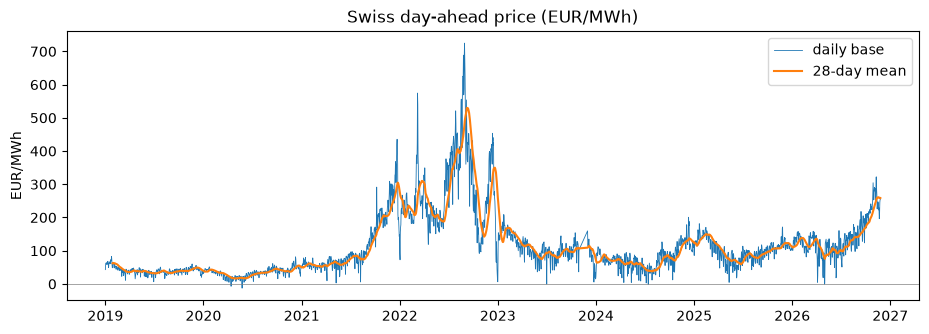

In [39]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily_ch["delivery_date"], daily_ch["base"], lw=0.6, label="daily base")
ax.plot(daily_ch["delivery_date"], daily_ch["base"].rolling(28).mean(), lw=1.5, label="28-day mean")
ax.axhline(0, color="grey", lw=0.5)
ax.set(title="Swiss day-ahead price (EUR/MWh)", ylabel="EUR/MWh")
ax.legend()
plt.show()

## 2. Day-ahead features

- `da_ch_last`: mean price of the last delivery day already published at the gate closure
- `da_ch_mean7`: mean of the last 7 published delivery days
- `da_ch_block`: daily auctions only, price of the same 4-hour block on that day

**Hypothesis:** upwards reserve is more expensive when energy is more expensive (capacity kept free can't be sold);
downwards may be the opposite (a plant must be running to be able to go down).

In [40]:
feats_da = add_day_ahead_features(feats_ref, prices_ch)
FEATURE_COLS_DA = FEATURE_COLS_REF + DAY_AHEAD_FEATURES

assert len(feats_da) == len(feats_ref)

In [28]:
corr = {}
d = feats_da[feats_da["y"].notna()]
for (freq, direction), g in d.groupby(["freq", "direction"]):
    col = "da_ch_block" if freq == "daily" else "da_ch_mean7"
    corr[f"{freq} {direction} ({col})"] = g.groupby(g["gc"].dt.year).apply(
        lambda x: x[col].corr(x["y"], method="spearman")
    )
pd.DataFrame(corr).round(2)        # Spearman, within each year

,daily downwards (da_ch_block),daily upwards (da_ch_block),weekly downwards (da_ch_mean7),weekly upwards (da_ch_mean7)
gc,,,,
2018,-0.14,0.58,NaN,NaN
2019,-0.19,0.14,0.37,-0.12
2020,-0.26,0.31,-0.23,0.68
2021,0.28,0.29,0.48,0.71
2022,-0.18,0.11,-0.01,-0.24
2023,-0.22,0.30,0.03,-0.16
2024,-0.47,0.28,0.43,0.23
2025,-0.11,0.40,-0.20,0.19
2026,-0.10,0.14,0.36,-0.40


Spearman correlation, computed separately for each year (to avoid the 2022 effect, when everything
was expensive), between the reserve price `y` of each auction and the day-ahead price known at its
gate closure: `da_ch_block` (same 4-hour block, last published day) for daily auctions,
`da_ch_mean7` (mean of the last 7 published days) for weekly auctions.

**Daily**
- **Upwards:** positive in every year. To offer upward reserve, a plant must keep
  capacity free that it could otherwise sell: when energy is expensive, reserving costs more.
- **Downwards:** negative in 8 of the 9 years. To offer downward reserve, 
a plant must be running: when energy is cheap, running costs money, so downward reserve is more expensive.

**Weekly** 

No stable relation. Likely reasons:
- the feature is far from the product: the mean of the 7 days before the tuesday gate closure,
  over all hours, while the reserve covers the following week;
- bidders price the coming week with forward-looking information (forward prices, water value of
  the reservoirs), which the past week's day-ahead price does not capture.

## 3. Reference vs day-ahead

Two walk-forwards on the validation period. The only difference between the two models
is the three day-ahead columns.

In [29]:
preds_ref = walk_forward_lgbm(feats_ref, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS_REF)
preds_da = walk_forward_lgbm(feats_da, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS_DA)

In [30]:
baseline = PreviousKnownAuctionBaseline().fit(auctions_all)
contracts = {
    "baseline": baseline.predict(auctions_all[in_val]),
    "lgbm_otherdir": to_contract(preds_ref, "lgbm_otherdir"),
    "lgbm_dayahead": to_contract(preds_da, "lgbm_dayahead"),
}
evaluator = Evaluator(actuals=auctions_all, start_test=VAL_START, end_test=VAL_END)
report = evaluator.evaluate_many(contracts)
table = report.pivot_table(index=["freq", "direction"], columns="model",
                           values=["mae", "pinball_q10", "coverage_80"])
display(green(table))
display(mean_gap_table(table))

,coverage_80,mae,pinball_q10
mean gap to best,,,
baseline,,16.0%,
lgbm_dayahead,0.023,0.2%,0.4%
lgbm_otherdir,0.000,0.3%,1.4%


## 4. Feature gain of the day-ahead model

One p50 model per group, 300 trees, trained on data available before the validation period. Gain means total
reduction of the loss by the cuts on each feature.

In [31]:
importance = {}
before = feats_da[feats_da["avail"] < pd.Timestamp(VAL_START, tz="UTC")].dropna(subset=["y", "lag1"])
for (freq, direction), d in before.groupby(["freq", "direction"]):
    model = lgbm_quantile_model(0.5, 300).fit(d[FEATURE_COLS_DA], d["y"] - d["lag1"])
    gain = model.booster_.feature_importance(importance_type="gain")
    importance[f"{freq} {direction}"] = pd.Series(gain / gain.sum(), index=FEATURE_COLS_DA)

pd.DataFrame(importance).sort_values("daily downwards", ascending=False).round(3)

,daily downwards,daily upwards,weekly downwards,weekly upwards
da_ch_mean7,0.125,0.121,0.011,0.022
da_ch_last,0.120,0.143,0.017,0.023
mom1,0.100,0.059,0.298,0.260
other_lag1,0.078,0.057,0.058,0.123
daytype_workday,0.071,0.095,0.000,0.000
lag1,0.068,0.064,0.042,0.063
mom2,0.066,0.099,0.152,0.123
lag3,0.055,0.050,0.146,0.079
lag_std,0.052,0.045,0.166,0.126
other_gap,0.052,0.072,0.065,0.161


# 5. Reference + reservoir levels ##

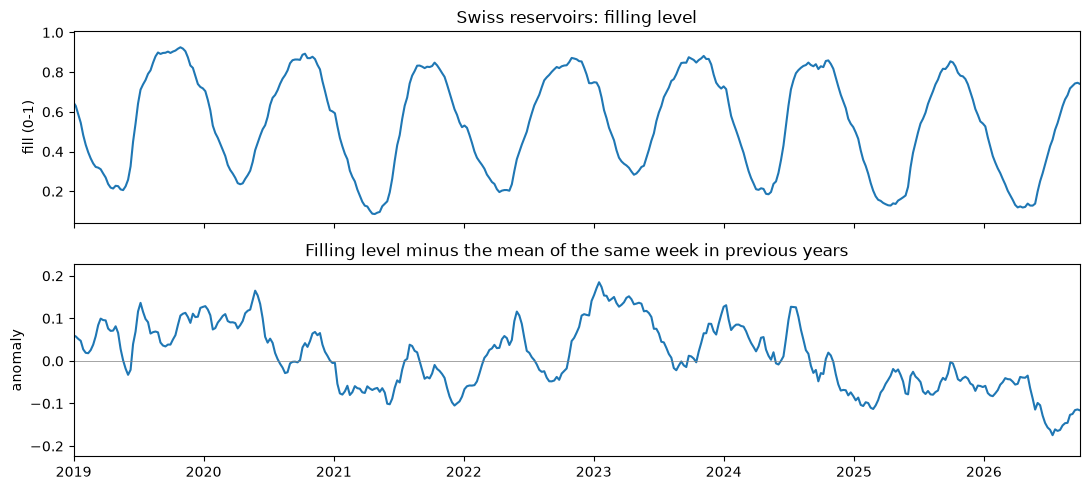

In [32]:
reservoirs = load_reservoirs(EXTERNAL / "reservoirs_ch.csv")
weekly_res = reservoir_weekly_features(reservoirs)

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(weekly_res["date"], weekly_res["res_fill"])
axes[0].set(title="Swiss reservoirs: filling level", ylabel="fill (0-1)")
axes[1].plot(weekly_res["date"], weekly_res["res_anomaly"])
axes[1].axhline(0, color="grey", lw=0.5)
axes[1].set(title="Filling level minus the mean of the same week in previous years", ylabel="anomaly")
axes[1].set_xlim(pd.Timestamp("2019-01-01"), weekly_res["date"].max())
plt.tight_layout()
plt.show()

In [33]:
feats_res = add_reservoir_features(feats_ref, reservoirs)
FEATURE_COLS_RES = FEATURE_COLS_REF + RESERVOIR_FEATURES
assert len(feats_res) == len(feats_ref)

d = feats_res[feats_res["y"].notna()]
corr = {}
for (freq, direction), g in d.groupby(["freq", "direction"]):
    corr[f"{freq} {direction}"] = g.groupby(g["gc"].dt.year).apply(
        lambda x: x["res_anomaly"].corr(x["y"], method="spearman")
    )
pd.DataFrame(corr).round(2)    

,daily downwards,daily upwards,weekly downwards,weekly upwards
gc,,,,
2018,-0.07,-0.19,NaN,NaN
2019,0.29,0.06,0.12,-0.35
2020,-0.15,-0.08,-0.01,-0.65
2021,0.25,0.06,-0.03,0.10
2022,-0.18,-0.12,-0.16,-0.51
2023,-0.07,0.07,0.38,0.29
2024,-0.62,-0.04,-0.35,0.32
2025,-0.13,-0.03,-0.05,-0.06
2026,-0.24,0.29,-0.37,0.88


To offer downward reserve, a hydro plant must be producing during the whole reserved period, that is use water continuously: when reservoirs
are emptier than usual, this water is more valuable, so downward reserve should be more expensive
(negative correlation). Daily downwards is the closest to this (5 of 7 years negative, -0.62 in
2024), but with two positive years and mostly weak values. Upward reserve only uses water when
activated, so a weaker link is expected, and indeed daily upwards is close to 0 in every year.
Overall, the correlation is not stable as its sign changes from year to year.

Note: the reservoir level changes only once a week, so all daily auctions of the same week share the
same value.

In [34]:
preds_res = walk_forward_lgbm(feats_res, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS_RES)

contracts["lgbm_reservoirs"] = to_contract(preds_res, "lgbm_reservoirs")
report = evaluator.evaluate_many(contracts)
table = report.pivot_table(index=["freq", "direction"], columns="model",
                           values=["mae", "pinball_q10", "coverage_80"])
display(green(table))
display(mean_gap_table(table))

,coverage_80,mae,pinball_q10
mean gap to best,,,
baseline,,16.2%,
lgbm_dayahead,0.036,0.5%,0.4%
lgbm_otherdir,0.013,0.5%,1.4%
lgbm_reservoirs,0.012,1.1%,2.7%


## Bidding Simulation ##

In [35]:
STRATEGIES = {
    "bid p50":       lambda c: c["marginal_price_pred"],
    "bid p10":       lambda c: c.get("marginal_price_p10"),
    "bid 0.9 x p50": lambda c: 0.9 * c["marginal_price_pred"],
}

def simulate_bids(contract, auctions, bid):
    df = contract[["auction_id"]].assign(bid=bid.to_numpy()).merge(
        auctions[["auction_id", "freq", "direction", "gc", "marginal"]], on="auction_id")
    df["accepted"] = df["marginal"].notna() & (df["bid"] <= df["marginal"])
    df["revenue"] = np.where(df["accepted"], df["bid"], 0.0)
    df["perfect"] = df["marginal"].fillna(0.0)
    df["year"] = df["gc"].dt.year
    return df

rows = []
for name, contract in contracts.items():
    for strategy, make_bid in STRATEGIES.items():
        bid = make_bid(contract)
        if bid is None:
            continue
        sim = simulate_bids(contract, auctions_all, bid)
        g = sim.groupby(["freq", "direction", "year"])
        rows.append(pd.DataFrame({
            "model": name, "strategy": strategy,
            "revenue": g["revenue"].sum(), "perfect": g["perfect"].sum(), "accepted": g["accepted"].mean(),
        }).reset_index())
sims = pd.concat(rows, ignore_index=True)

annual = sims.groupby(["freq", "direction", "model", "strategy"])[["revenue", "perfect"]].sum() / sims["year"].nunique()
annual["share"] = annual["revenue"] / annual["perfect"]

print("Mean revenue per year (CHF per MW offered)")
display(green(annual["revenue"].unstack(["model", "strategy"]), "revenue"))
best_revenue = annual["revenue"].unstack(["model", "strategy"]).T.groupby(level="model").max().T   # best strategy of each model
display(mean_gap_table(best_revenue, "revenue"))

print("Share of the perfect revenue")
display(green(annual["share"].unstack(["model", "strategy"]), "share"))

Mean revenue per year (CHF per MW offered)


,revenue
mean gap to best,
baseline,21.5%
lgbm_dayahead,2.6%
lgbm_otherdir,1.2%
lgbm_reservoirs,1.5%


Share of the perfect revenue


In [36]:
print("Share of accepted bids")
accepted = sims.groupby(["freq", "direction", "model", "strategy"])["accepted"].mean().unstack(["model", "strategy"])
display(accepted.style.highlight_max(axis=1, props="background-color: #c6efce; color: #006100; font-weight: bold")
        .format("{:.0%}"))

Share of accepted bids


## Conclusion

Two external sources were tested, one at a time, against the reference model `lgbm_otherdir` on the
validation period 2022–2024, with every value used only after its publication.

| experiment | MAE | p10 pinball | coverage 80% | revenue | decision |
|---|---|---|---|---|---|
| + day-ahead CH | tie (mean gap 0.2% vs 0.3%) | slightly better in 3 of 4 groups | further from 0.80 in all 4 groups | ±1–2% depending on the group | not kept |
| + reservoirs | better in daily downwards, +4% in daily upwards | worse in all 4 groups | further from 0.80 in 3 groups | ±1–3% depending on the group | not kept |

- **Day-ahead prices.** There is a real relation in the daily groups , consistent with the opportunity cost of
  reserving capacity. But it is a relation with the price level, which `lag1` already contains, while the
  model predicts the change; and since every reserve auction closes before the day-ahead auction of its
  own delivery day, the information is about as old as `lag1`. 
- **Reservoir levels.** No stable relation with the reserve price. The
  level changes only once a week and slowly, so a tree can use it as a "clock" for periods of the training
  data, which may explain the worse daily upwards. 
- **Decision: no external data in the final model.** The reference `lgbm_otherdir` is kept. The most
  promising external input for the weekly auctions would be forward prices for the delivery week, which
  were not available.